# Integral against pulse height, channel by channel (-82 V, DCRC1pB trigger)

*Tenth notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

For each of the six channels, the `integral` of every real trigger against its **pulse height**: the largest sample above the baseline, `current_max` of `goldsluice`'s `peak` (with `amps_per_adc` = 1 it is in ADC counts, equal to `adc_max - baseline_mean`). No cut on the position. Both quantities use the same baseline, the mean of samples 10 to 500.

For a pulse of fixed shape the integral is proportional to the height. Saturation breaks that: once a channel reaches its saturated height, the height stops growing and only the integral does (the flat top gets longer), up to the integral of a pulse held at that height to the end of the trace. The dotted lines mark both: the saturated height (the 99.99th percentile of the height) and the largest integral it allows (that height times the 2.88 ms from the trigger to the end of the trace).

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors

from goldpan.adapters import parquet
from spots_82v import LETTERS, OUT

q = parquet.read(OUT, detector="NAI-S2").quantities
real = np.asarray(q["trigger_type"]).astype(str) == "Unknown"
I = {k: np.asarray(q[f"Side2p{k}"]["integral"], dtype=float)[real] for k in LETTERS}         # ADC counts x s
H = {k: np.asarray(q[f"Side2p{k}"]["current_max"], dtype=float)[real] for k in LETTERS}      # ADC counts above the baseline
T_AFTER = (4096 - 500) * 0.8e-6            # seconds from the trigger (sample 500) to the end of the trace
H_SAT = {k: np.percentile(H[k], 99.99) for k in LETTERS}

print(f"{real.sum():,} real triggers")
print(f"{'':28}" + "".join(f"{'Side2p' + k:>10}" for k in LETTERS))
print(f"{'saturated height (counts)':28}" + "".join(f"{H_SAT[k]:>10.0f}" for k in LETTERS))
print(f"{'its largest integral':28}" + "".join(f"{H_SAT[k] * T_AFTER:>10.2f}" for k in LETTERS))
print(f"{'height above 2000 (glitch?)':28}" + "".join(f"{(H[k] > 2000).sum():>10,}" for k in LETTERS))

1,436,655 real triggers
                               Side2pA   Side2pB   Side2pC   Side2pD   Side2pE   Side2pF
saturated height (counts)         1322      1105       598       938       688       897
its largest integral              3.80      3.18      1.72      2.70      1.98      2.58
height above 2000 (glitch?)         27        36        55         5         8        20


## All six channels

The density of events in the plane of height and integral, on a log colour scale, one panel per channel, all on the same axes. A few events have a height of thousands of counts (a single-sample spike far above any pulse, counted in the table above); they are outside the plotted range.

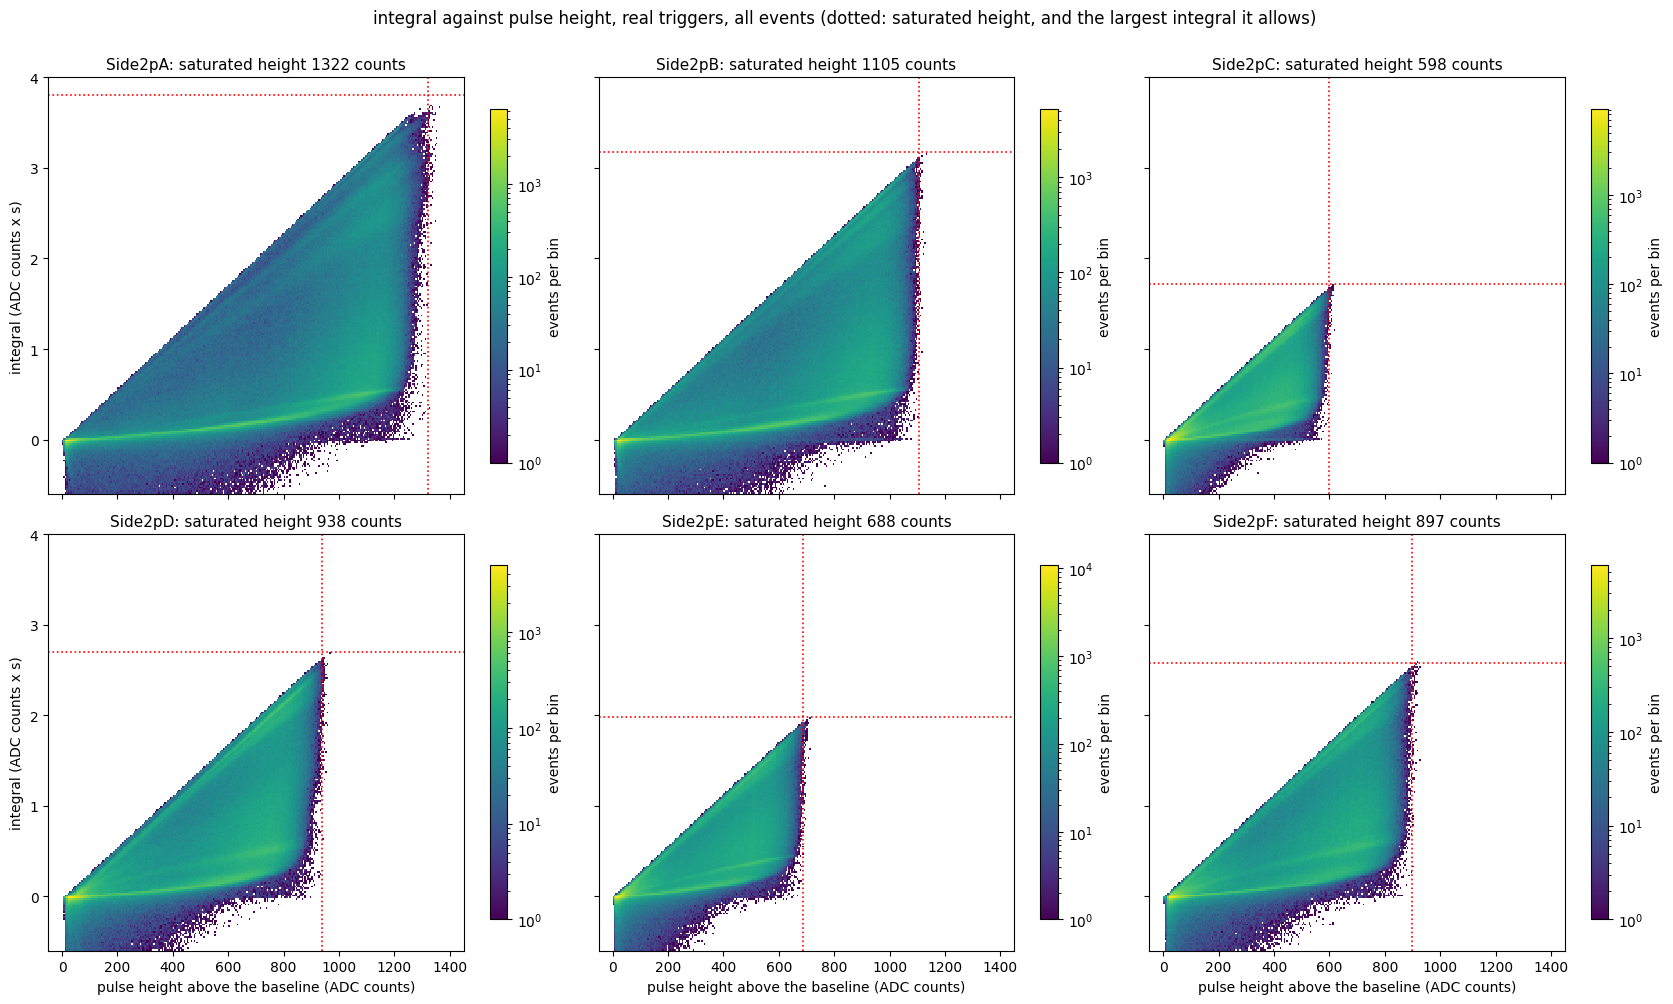

In [2]:
HR, IR = (-50, 1450), (-0.6, 4.0)
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for ax, k in zip(axes.flat, LETTERS):
    h = ax.hist2d(H[k], I[k], bins=[300, 230], range=[HR, IR], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.axhline(H_SAT[k] * T_AFTER, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}: saturated height {H_SAT[k]:.0f} counts", fontsize=11)
    fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
for ax in axes[-1]:
    ax.set_xlabel("pulse height above the baseline (ADC counts)")
for ax in axes[:, 0]:
    ax.set_ylabel("integral (ADC counts x s)")
fig.suptitle("integral against pulse height, real triggers, all events (dotted: saturated height, and the largest integral it allows)", y=1.0)
fig.tight_layout()
plt.show()

## Integral per unit height

The ratio `integral / height` is the effective length of the pulse (in seconds): constant for pulses of one shape, growing as the flat top of a saturated pulse lengthens. Plotted against the height, for events with a height above 50 counts (below that the ratio is mostly noise).

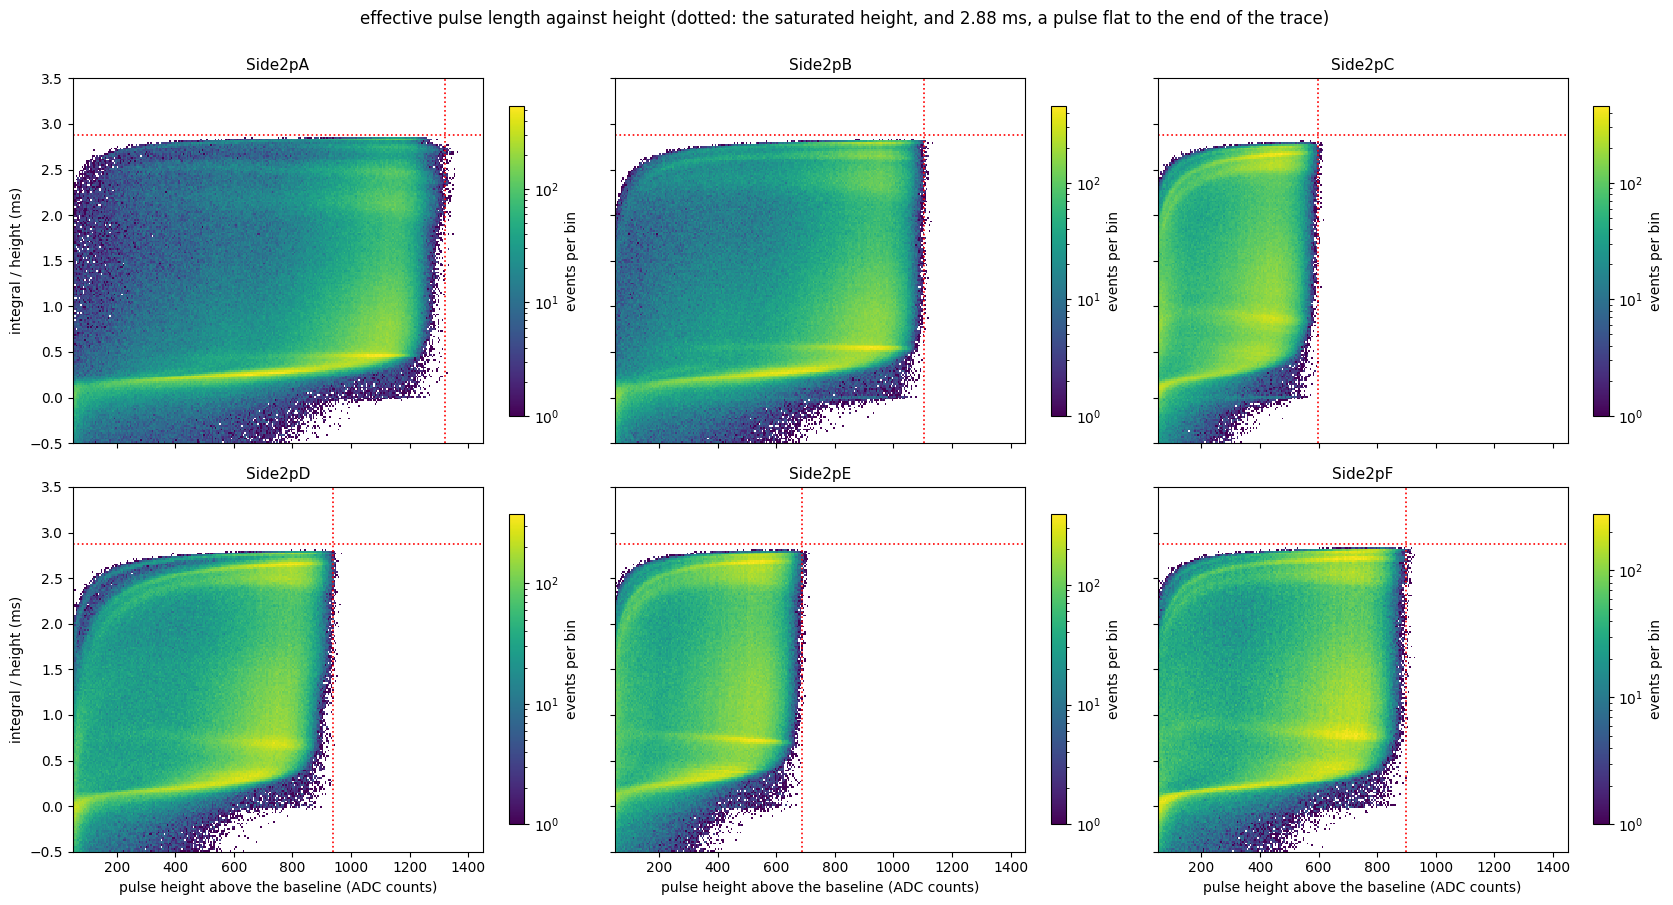

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
for ax, k in zip(axes.flat, LETTERS):
    m = H[k] > 50
    h = ax.hist2d(H[k][m], I[k][m] / H[k][m] * 1e3, bins=[280, 200], range=[(50, 1450), (-0.5, 3.5)],
                  cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.axhline(T_AFTER * 1e3, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}", fontsize=11)
    fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
for ax in axes[-1]:
    ax.set_xlabel("pulse height above the baseline (ADC counts)")
for ax in axes[:, 0]:
    ax.set_ylabel("integral / height (ms)")
fig.suptitle("effective pulse length against height (dotted: the saturated height, and 2.88 ms, a pulse flat to the end of the trace)", y=1.0)
fig.tight_layout()
plt.show()

## Side2pF: the three straight bands

In the plane of integral and height, Side2pF shows three straight bands through the origin, besides the curved main band of the clean pulses at the bottom. A straight line through the origin is a constant ratio `integral / height`, so each band is a horizontal stripe in the second figure: at about **0.8 ms**, **2.55 ms** and **2.7 ms**. The two upper ones bend down below a height of about 300 counts, so each cut is a window in the ratio **and** in the height, where the band is sharpest:

| band | ratio (ms) | height (counts) |
|---|---|---|
| 0.8 ms | 0.76 to 0.84 | 600 to 800 |
| 2.55 ms | 2.50 to 2.58 | 400 to 700 |
| 2.7 ms | 2.68 to 2.76 | 600 to 800 |

The bands sit on a broad continuum, so **a cut does not select only band events**: comparing each window with the two windows of the same width on either side of it, roughly 20 to 40 % of the events in a window are in excess of the continuum (an underestimate, since the side windows hold the bands' own tails). The sample pulses below will mix band events with the continuum.

band   0.8 ms:  31,372 events; side windows    24,436 on average -> about 22% in excess of the continuum
band  2.55 ms:  21,295 events; side windows    17,768 on average -> about 17% in excess of the continuum
band   2.7 ms:  28,265 events; side windows    17,240 on average -> about 39% in excess of the continuum


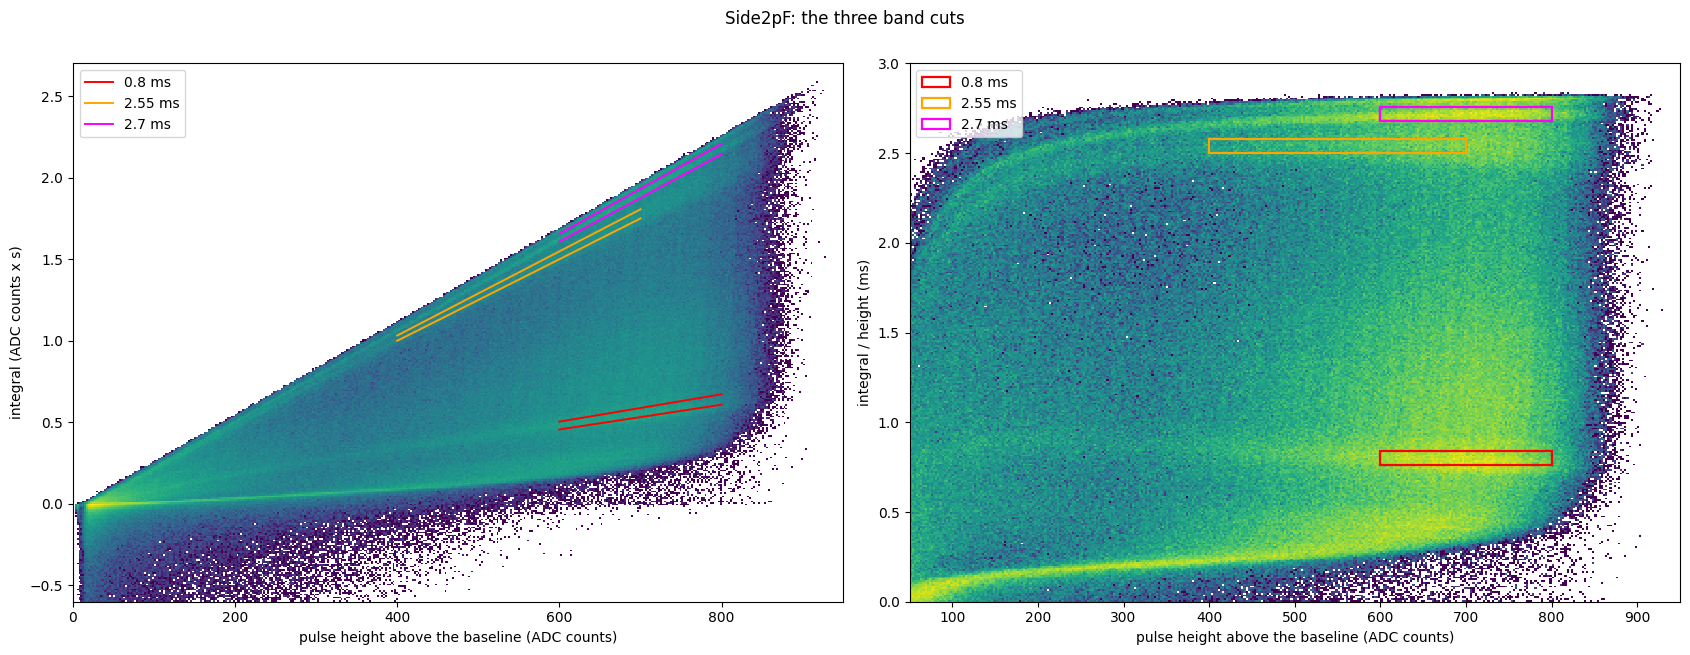

In [4]:
BANDS = {                                  # name -> (ratio low, ratio high in ms, height low, height high in counts)
    "0.8 ms": (0.76, 0.84, 600, 800),
    "2.55 ms": (2.50, 2.58, 400, 700),
    "2.7 ms": (2.68, 2.76, 600, 800),
}
HF, IF = H["F"], I["F"]
RF = np.full_like(HF, np.nan)
RF[HF > 0] = IF[HF > 0] / HF[HF > 0] * 1e3        # ms
band = {b: (RF > lo) & (RF < hi) & (HF > hl) & (HF < hh) for b, (lo, hi, hl, hh) in BANDS.items()}
for b, (lo, hi, hl, hh) in BANDS.items():
    side = (((RF > 2 * lo - hi) & (RF < lo)) | ((RF > hi) & (RF < 2 * hi - lo))) & (HF > hl) & (HF < hh)
    print(f"band {b:>8}: {band[b].sum():>7,} events; side windows {side.sum() / 2:>9,.0f} on average "
          f"-> about {1 - side.sum() / 2 / band[b].sum():.0%} in excess of the continuum")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
axes[0].hist2d(HF, IF, bins=[400, 330], range=[(0, 950), (-0.6, 2.7)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
m = HF > 50
axes[1].hist2d(HF[m], RF[m], bins=[360, 300], range=[(50, 950), (0, 3)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
for (b, (lo, hi, hl, hh)), c in zip(BANDS.items(), ("r", "orange", "magenta")):
    axes[1].add_patch(plt.Rectangle((hl, lo), hh - hl, hi - lo, facecolor="none", edgecolor=c, linewidth=1.6, label=b))
    for r in (lo, hi):                              # the same window in the integral-height plane: two lines through the origin
        hs = np.array([hl, hh])
        axes[0].plot(hs, hs * r * 1e-3, color=c, linewidth=1.4, label=b if r == lo else None)
axes[0].set_xlabel("pulse height above the baseline (ADC counts)")
axes[0].set_ylabel("integral (ADC counts x s)")
axes[1].set_xlabel("pulse height above the baseline (ADC counts)")
axes[1].set_ylabel("integral / height (ms)")
for ax in axes:
    ax.legend(loc="upper left")
fig.suptitle("Side2pF: the three band cuts", y=1.0)
fig.tight_layout()
plt.show()

### Sample Side2pF pulses from each band

Twelve randomly chosen events of each cut, read from the raw dumps in `~/idx` (Side2pF only), baseline subtracted with the same baseline as `integral` (the mean of samples 10 to 500, shaded grey). Each tile gives the event, its height and its ratio. The dotted line is the end of the trace, where the integral stops.

read 36 Side2pF traces; largest difference from the processed integral: 1.4e-13


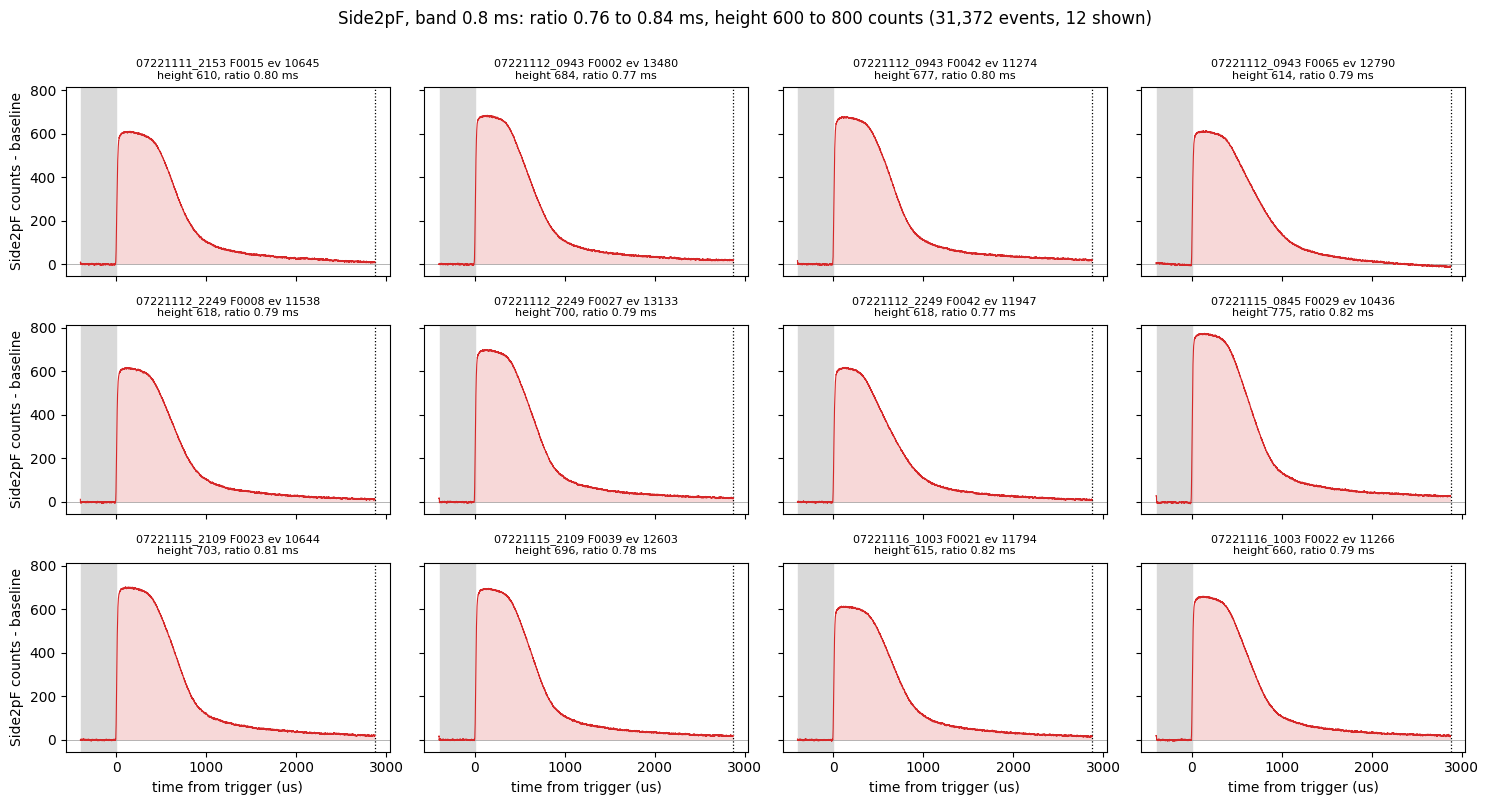

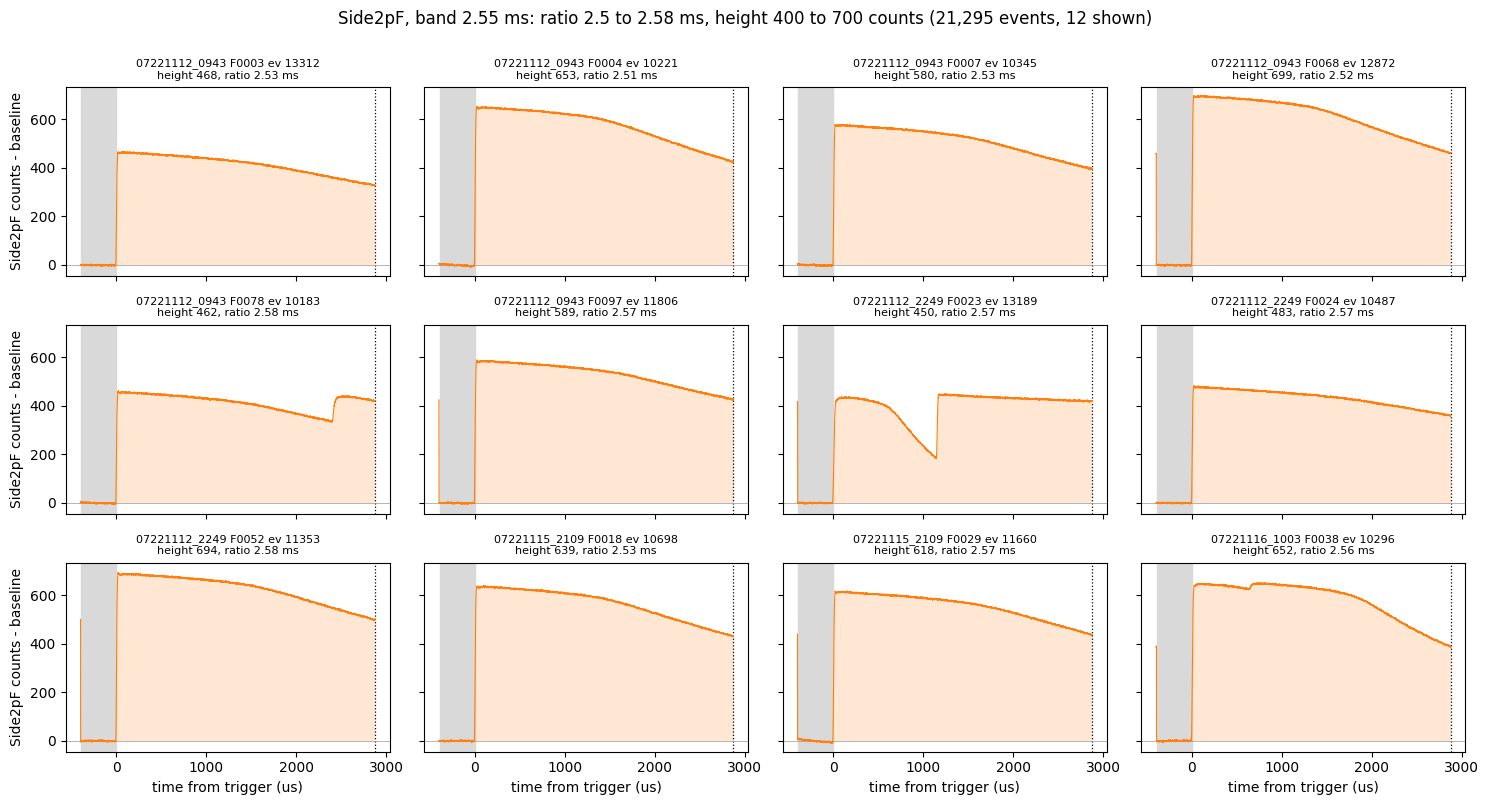

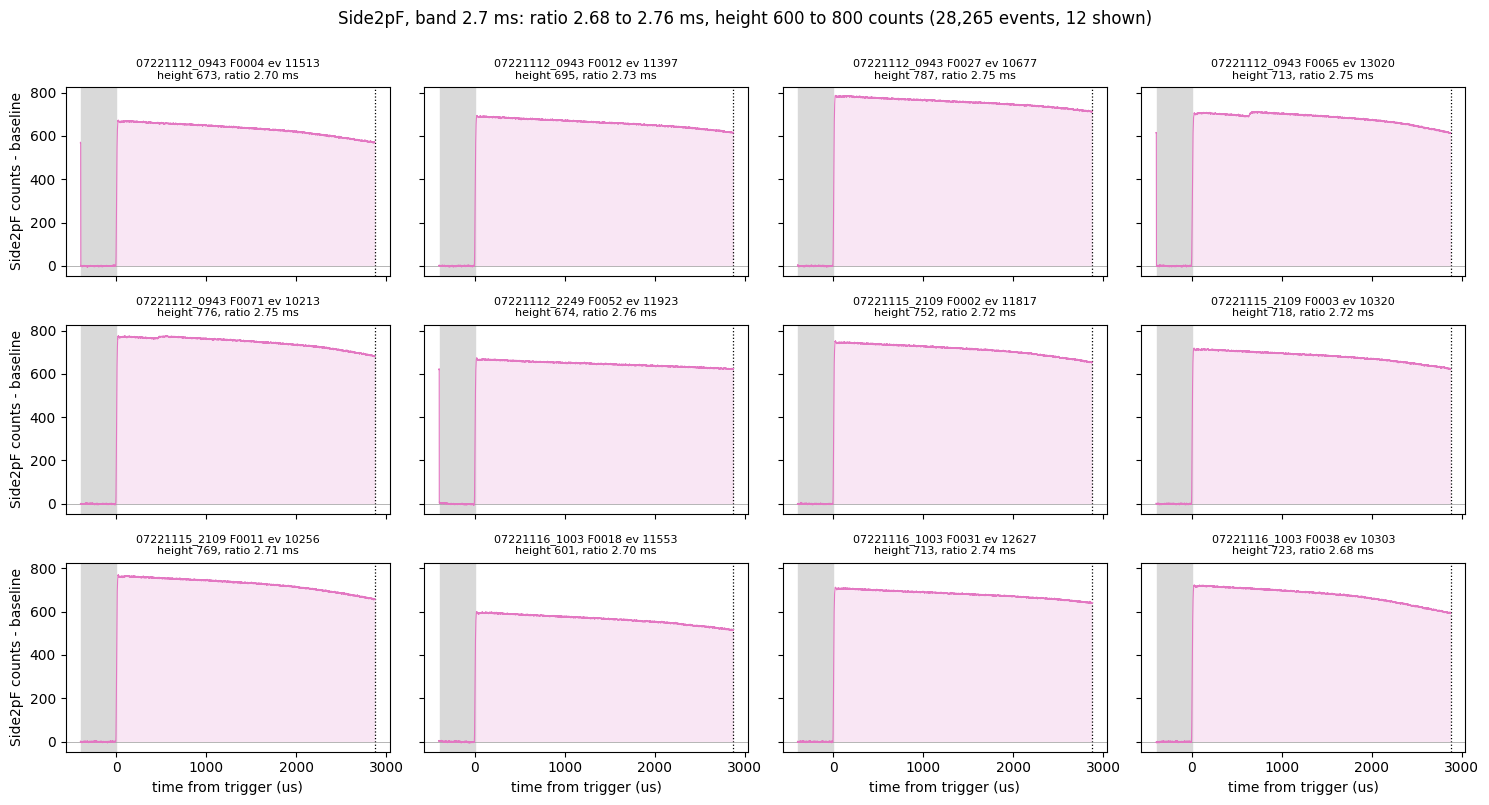

In [5]:
from pathlib import Path

from goldpan.adapters import idx
from goldpan.config import DCRC_RUN76

RAW = Path.home() / "idx"
N_SAMPLE, SEED = 12, 1
SER = np.asarray(q["series"]).astype(str)[real]
DMP = np.asarray(q["dump"]).astype(str)[real]
EVT = np.asarray(q["event"])[real]
g, p = DCRC_RUN76.glitch_samples, DCRC_RUN76.pretrigger_samples
t_us = (np.arange(4096) - p) * DCRC_RUN76.sample_period_s * 1e6

rng = np.random.default_rng(SEED)
picked = {b: np.sort(rng.choice(np.flatnonzero(band[b]), N_SAMPLE, replace=False)) for b in BANDS}
traces = {}
for s, dmp in sorted({(SER[i], DMP[i]) for b in BANDS for i in picked[b]}):
    ev = idx.read(RAW / (dmp if dmp.startswith(s) else f"{s}_{dmp}"), detector_name="NAI-S2",
                  channels={"Side2pF": (0, 1)}, config=DCRC_RUN76)
    numbers = np.asarray(ev.quantities["event"])
    key = next(iter(ev.traces))
    for b in BANDS:
        for i in picked[b]:
            if (SER[i], DMP[i]) == (s, dmp):
                x = np.asarray(ev.traces[key][int(np.flatnonzero(numbers == EVT[i])[0])], dtype=float)
                traces[i] = x - x[g:p].mean()
worst = max(abs(traces[i].sum() * DCRC_RUN76.sample_period_s - IF[i]) for i in traces)
print(f"read {len(traces)} Side2pF traces; largest difference from the processed integral: {worst:.1e}")

for (b, (lo, hi, hl, hh)), c in zip(BANDS.items(), ("C3", "C1", "C6")):
    fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True, sharey=True)
    for ax, i in zip(axes.flat, picked[b]):
        ax.axvspan(t_us[g], 0, color="0.85", zorder=0)
        ax.axvline(t_us[-1], color="k", linestyle=":", linewidth=0.9)
        ax.axhline(0, color="0.6", linewidth=0.5)
        ax.fill_between(t_us, traces[i], 0, color=c, alpha=0.18, linewidth=0)
        ax.plot(t_us, traces[i], color=c, linewidth=0.8)
        ax.set_title(f"{SER[i]} {DMP[i]} ev {EVT[i]}\nheight {HF[i]:.0f}, ratio {RF[i]:.2f} ms", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("time from trigger (us)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Side2pF counts - baseline")
    fig.suptitle(f"Side2pF, band {b}: ratio {lo} to {hi} ms, height {hl} to {hh} counts ({band[b].sum():,} events, {N_SAMPLE} shown)", y=1.0)
    fig.tight_layout()
    plt.show()

The twelve samples of each band overlaid, each divided by its own height, so the shapes can be compared directly.

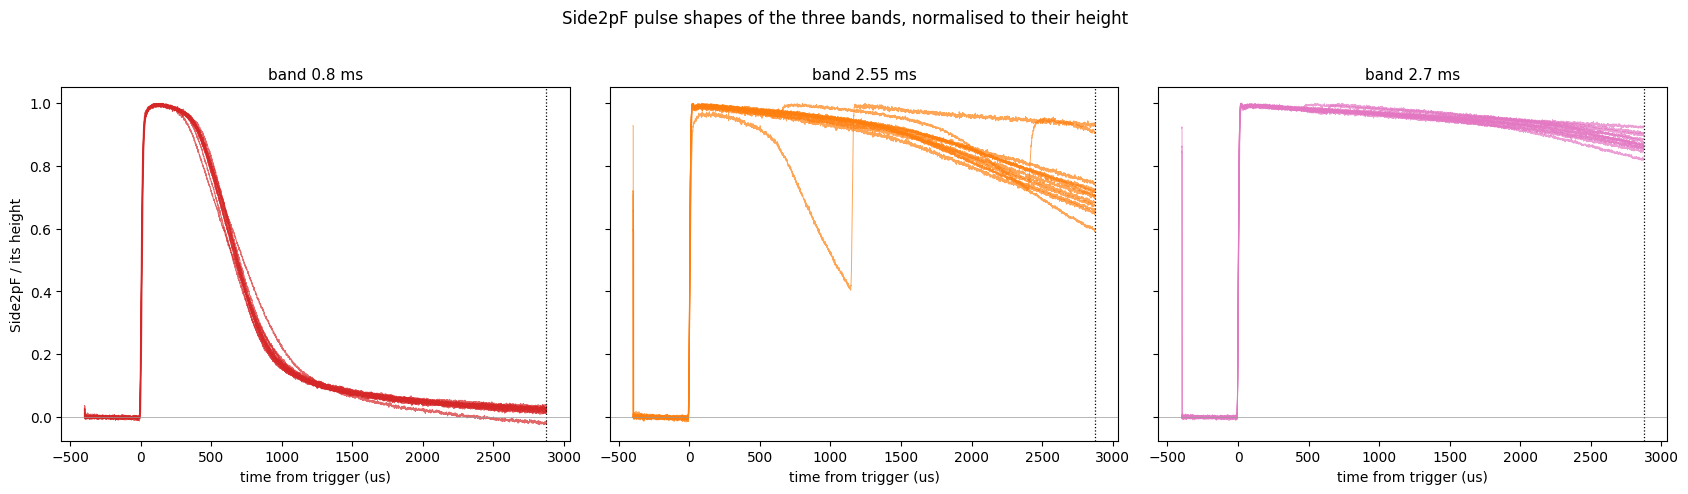

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
for ax, (b, c) in zip(axes, zip(BANDS, ("C3", "C1", "C6"))):
    for i in picked[b]:
        ax.plot(t_us, traces[i] / HF[i], color=c, linewidth=0.7, alpha=0.7)
    ax.axvline(t_us[-1], color="k", linestyle=":", linewidth=0.9)
    ax.axhline(0, color="0.6", linewidth=0.5)
    ax.set_title(f"band {b}", fontsize=11)
    ax.set_xlabel("time from trigger (us)")
axes[0].set_ylabel("Side2pF / its height")
fig.suptitle("Side2pF pulse shapes of the three bands, normalised to their height", y=1.02)
fig.tight_layout()
plt.show()

## The 0.8 ms band alone, down to small heights

The 0.8 ms band of Side2pF followed from its saturated end down toward zero. Its ratio is not quite constant: the ridge of the band (the peak of the ratio distribution in slices of height) moves from about 0.78 ms at a height of 800 counts to about 0.89 ms at 200 counts. The cut follows that ridge, a straight line in height, with a window of +-0.04 ms around it, from a height of `H_MIN` = 50 counts up to 850:

`ridge(h) = 0.78 ms + (800 - h) x 1.8e-4 ms per count`,  `|integral / height - ridge(h)| < 0.04 ms`

At small heights the noise of the integral (about 0.1 ADC counts x s, the width of the random triggers) spreads the ratio by more than the window, so the band fades into the continuum: the table gives, slice by slice, the events in the window and the excess over two side windows of the same width just outside it (+-0.04 to 0.12 ms from the ridge).

the 0.8 ms band, heights 50 to 850: 63,503 events
      height  in window  side (same width)   excess
   50 to 100       1,780              1,943      -9%
  100 to 200       3,996              3,518      12%
  200 to 300       3,425              3,066      10%
  300 to 450       6,634              5,682      14%
  450 to 600      13,958             11,156      20%


  600 to 750      25,309             19,408      23%
  750 to 850       8,400              6,400      24%


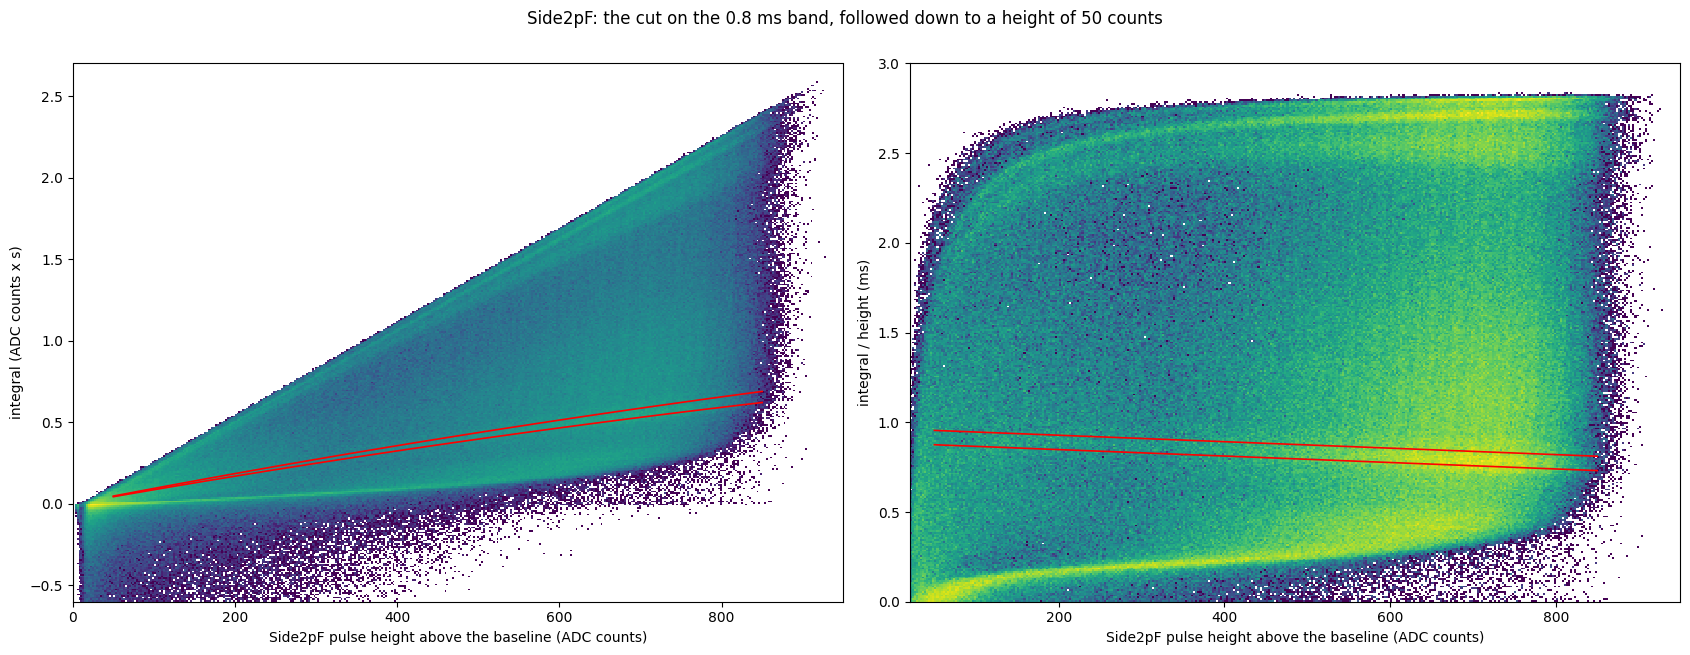

In [7]:
H_MIN, H_MAX, HALF = 50, 850, 0.04
def ridge(h):
    return 0.78 + (800 - h) * 1.8e-4                 # ms

dr = RF - ridge(HF)
line = (HF > H_MIN) & (HF < H_MAX) & (np.abs(dr) < HALF)
print(f"the 0.8 ms band, heights {H_MIN} to {H_MAX}: {line.sum():,} events")
print(f"{'height':>12} {'in window':>10} {'side (same width)':>18} {'excess':>8}")
for lo, hi in [(50, 100), (100, 200), (200, 300), (300, 450), (450, 600), (600, 750), (750, 850)]:
    s = (HF > lo) & (HF < hi)
    inside = (s & (np.abs(dr) < HALF)).sum()
    side = (s & (np.abs(dr) >= HALF) & (np.abs(dr) < 3 * HALF)).sum() / 2
    print(f"{lo:>5} to {hi:<4} {inside:>10,} {side:>18,.0f} {1 - side / inside:>8.0%}")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
hs = np.linspace(H_MIN, H_MAX, 50)
axes[0].hist2d(HF, IF, bins=[400, 330], range=[(0, 950), (-0.6, 2.7)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
m = HF > 20
axes[1].hist2d(HF[m], RF[m], bins=[372, 300], range=[(20, 950), (0, 3)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
for sgn in (-1, 1):
    axes[0].plot(hs, hs * (ridge(hs) + sgn * HALF) * 1e-3, color="r", linewidth=1.2)
    axes[1].plot(hs, ridge(hs) + sgn * HALF, color="r", linewidth=1.2)
axes[0].set_ylabel("integral (ADC counts x s)")
axes[1].set_ylabel("integral / height (ms)")
for ax in axes:
    ax.set_xlabel("Side2pF pulse height above the baseline (ADC counts)")
fig.suptitle("Side2pF: the cut on the 0.8 ms band, followed down to a height of 50 counts", y=1.0)
fig.tight_layout()
plt.show()

### All six channels, for the events of the 0.8 ms band

The integral against the height of every channel, for the events selected on Side2pF alone. If the band is one kind of event, the other channels should also fall on narrow lines.

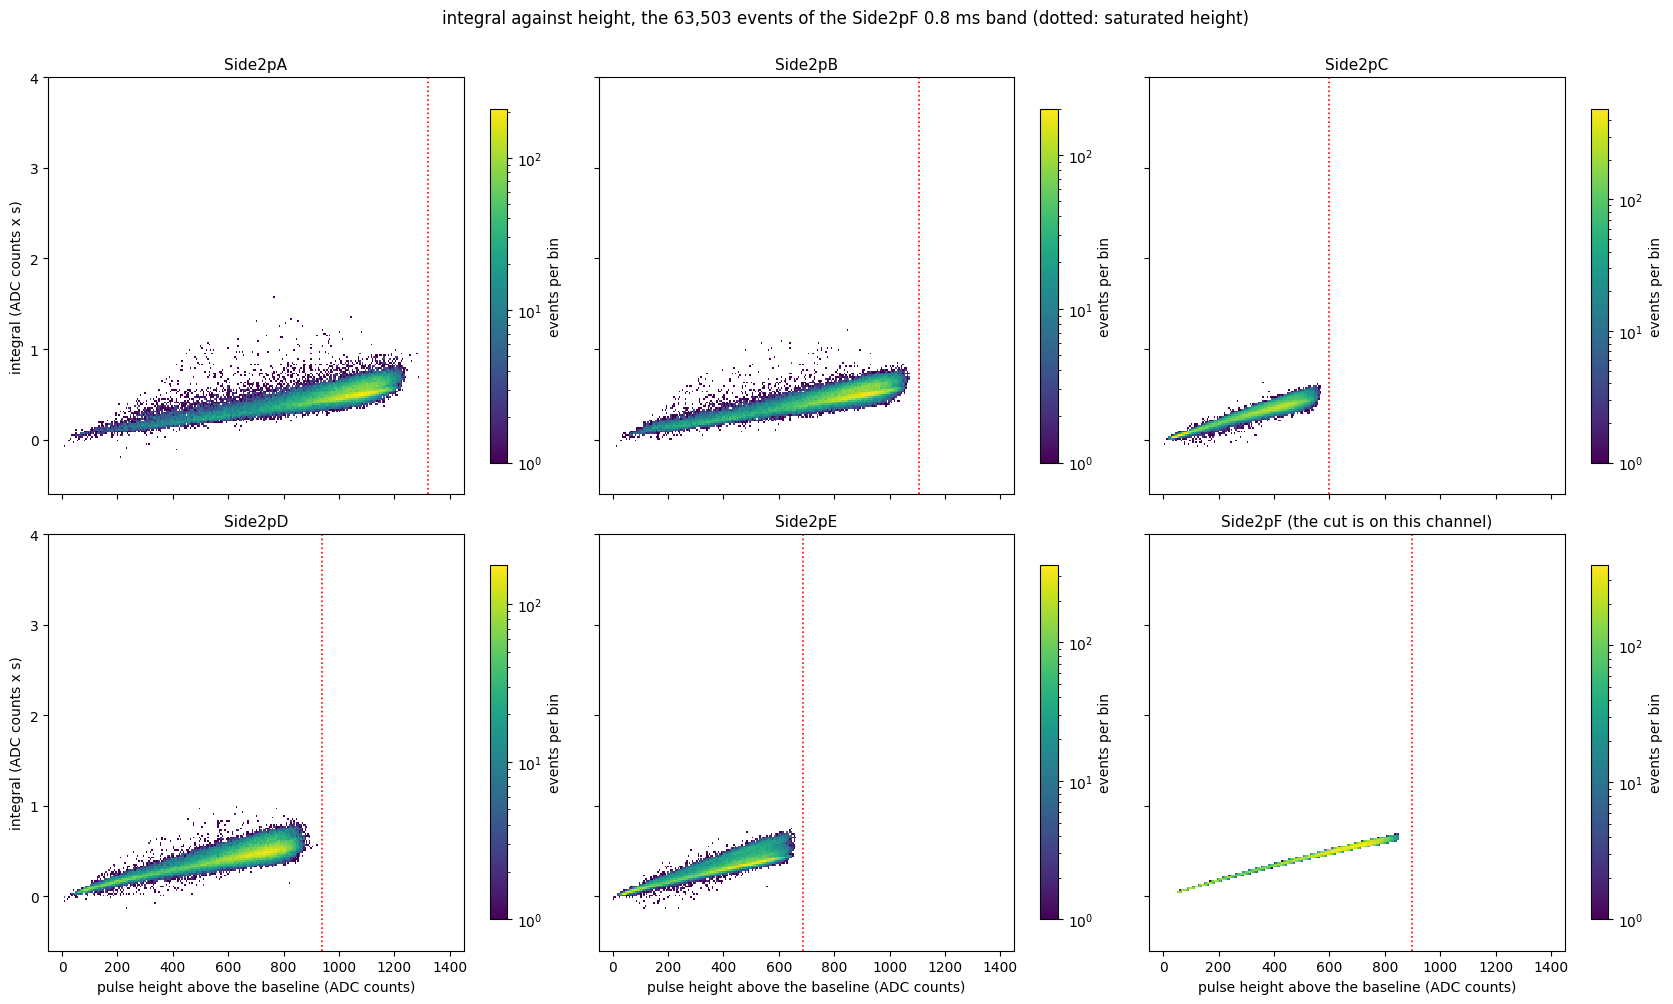

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for ax, k in zip(axes.flat, LETTERS):
    h = ax.hist2d(H[k][line], I[k][line], bins=[290, 230], range=[HR, IR], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}" + (" (the cut is on this channel)" if k == "F" else ""), fontsize=11)
    fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
for ax in axes[-1]:
    ax.set_xlabel("pulse height above the baseline (ADC counts)")
for ax in axes[:, 0]:
    ax.set_ylabel("integral (ADC counts x s)")
fig.suptitle(f"integral against height, the {line.sum():,} events of the Side2pF 0.8 ms band (dotted: saturated height)", y=1.0)
fig.tight_layout()
plt.show()

### Pulses along the band, all channels

Events spread along the band: the band is cut into `N_ALONG` equal slices of Side2pF height, and one event is chosen at random in each, so the selection runs from the smallest pulses to the saturated ones. Each event is drawn in all channels, in the tiled layout of the earlier notes (one row per readout board, one column per board input; the inputs that are not sensors are blank), baseline subtracted with the baseline of `integral` (the grey band); the dotted lines are the integration window, the whole trace. The channels of an event share one vertical scale.

C:\Users\Anthony\AppData\Local\Temp\ipykernel_4056\219779763.py:7: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
C:\Users\Anthony\AppData\Local\Temp\ipykernel_4056\219779763.py:9: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  INFO = {key: pch.channel_info(*key) for key in KEYS}


8 events; largest difference from the processed integrals: 1.2e-13


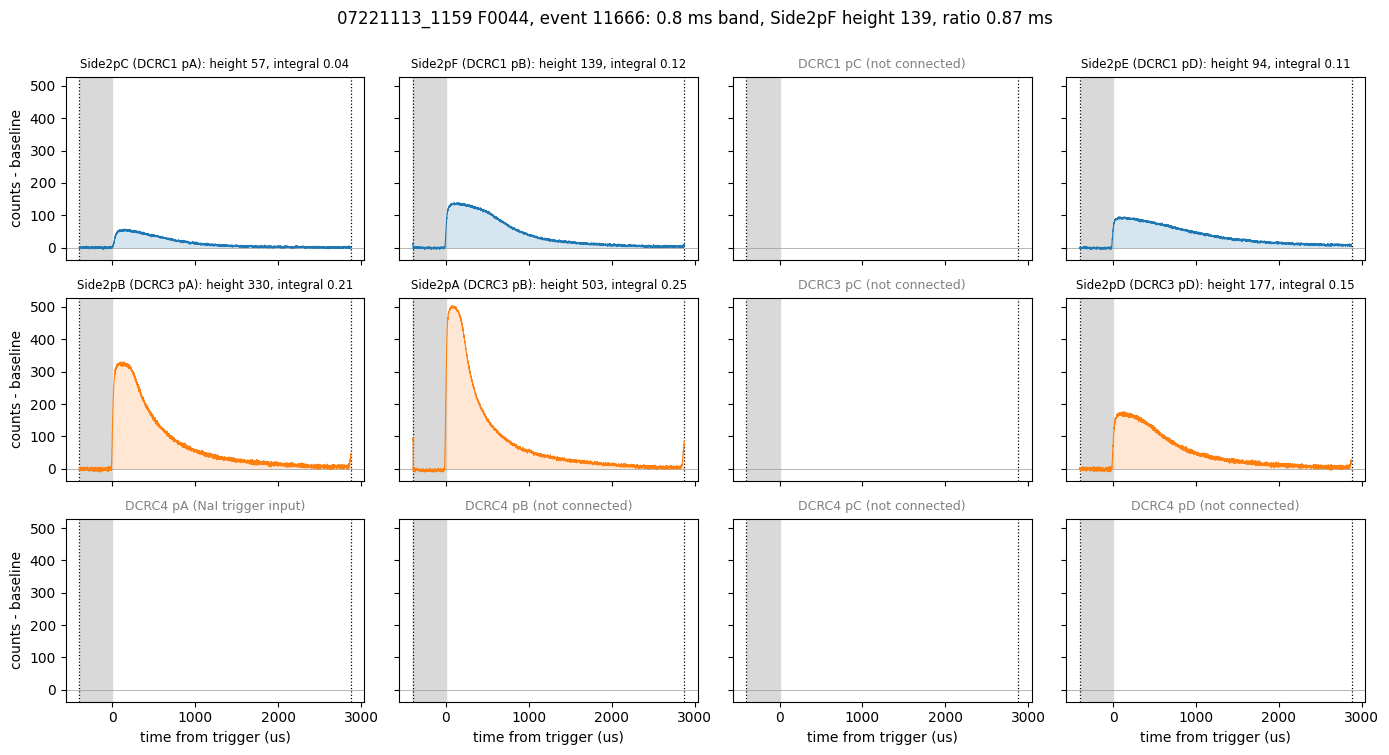

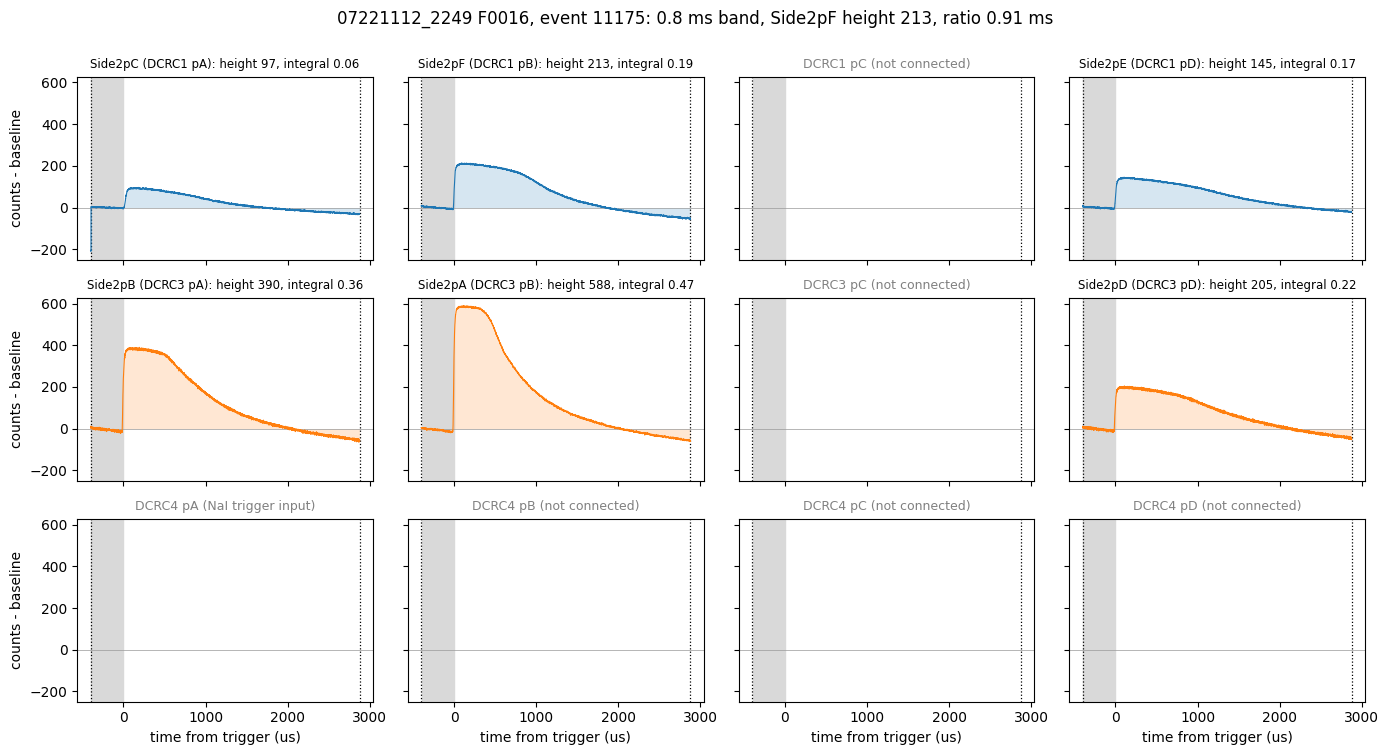

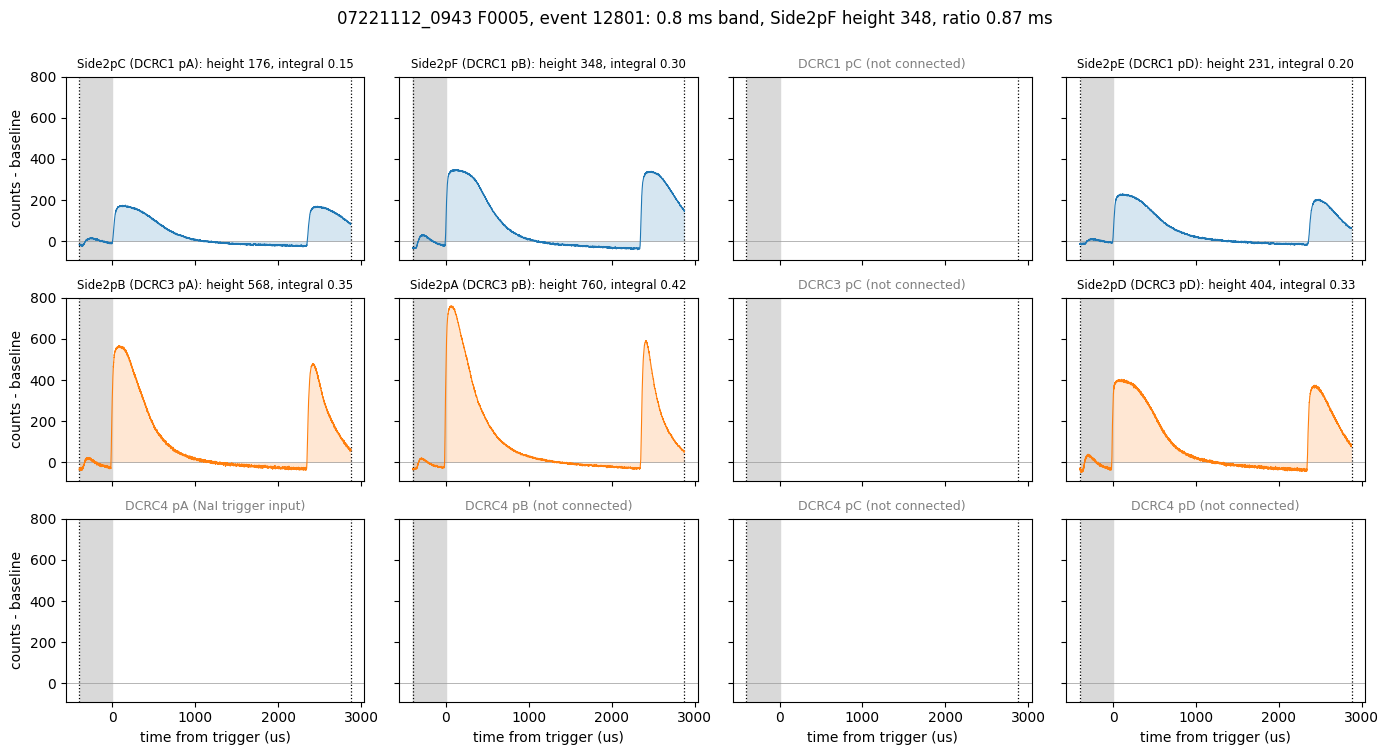

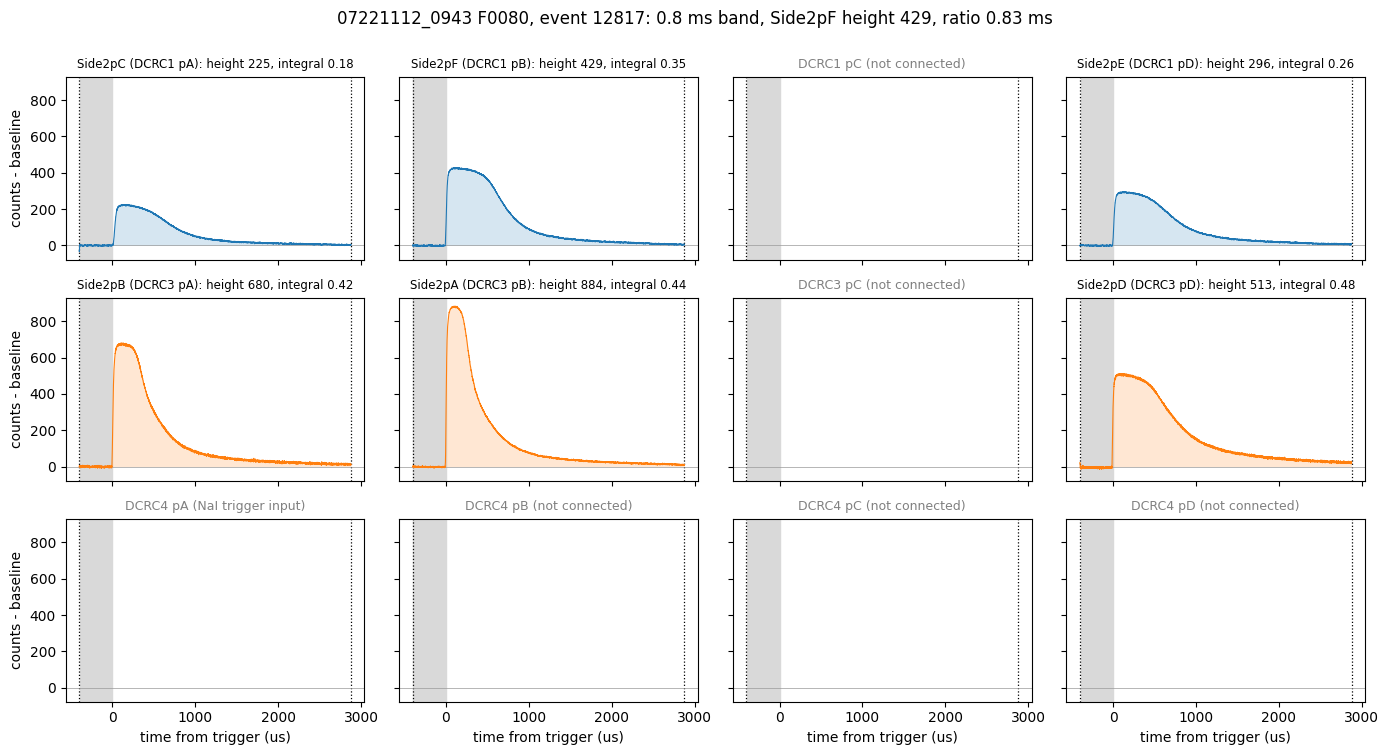

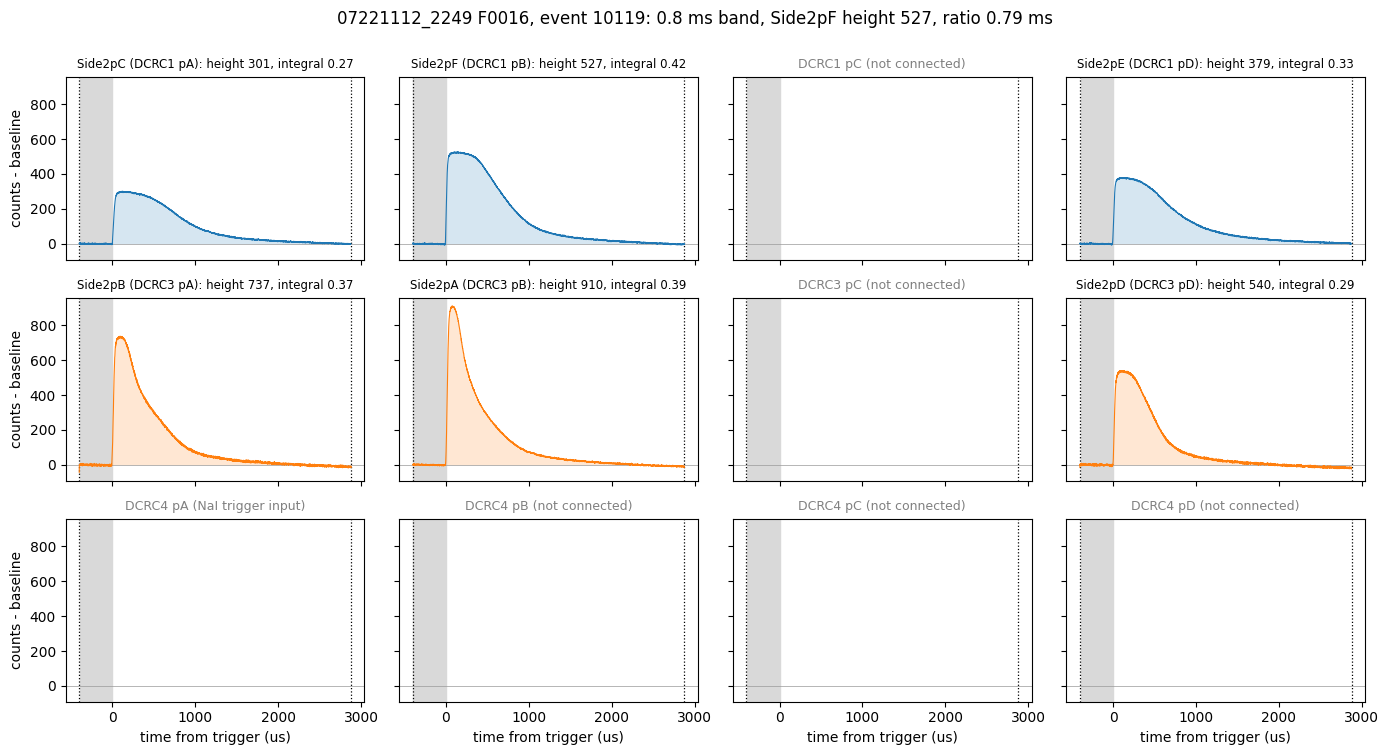

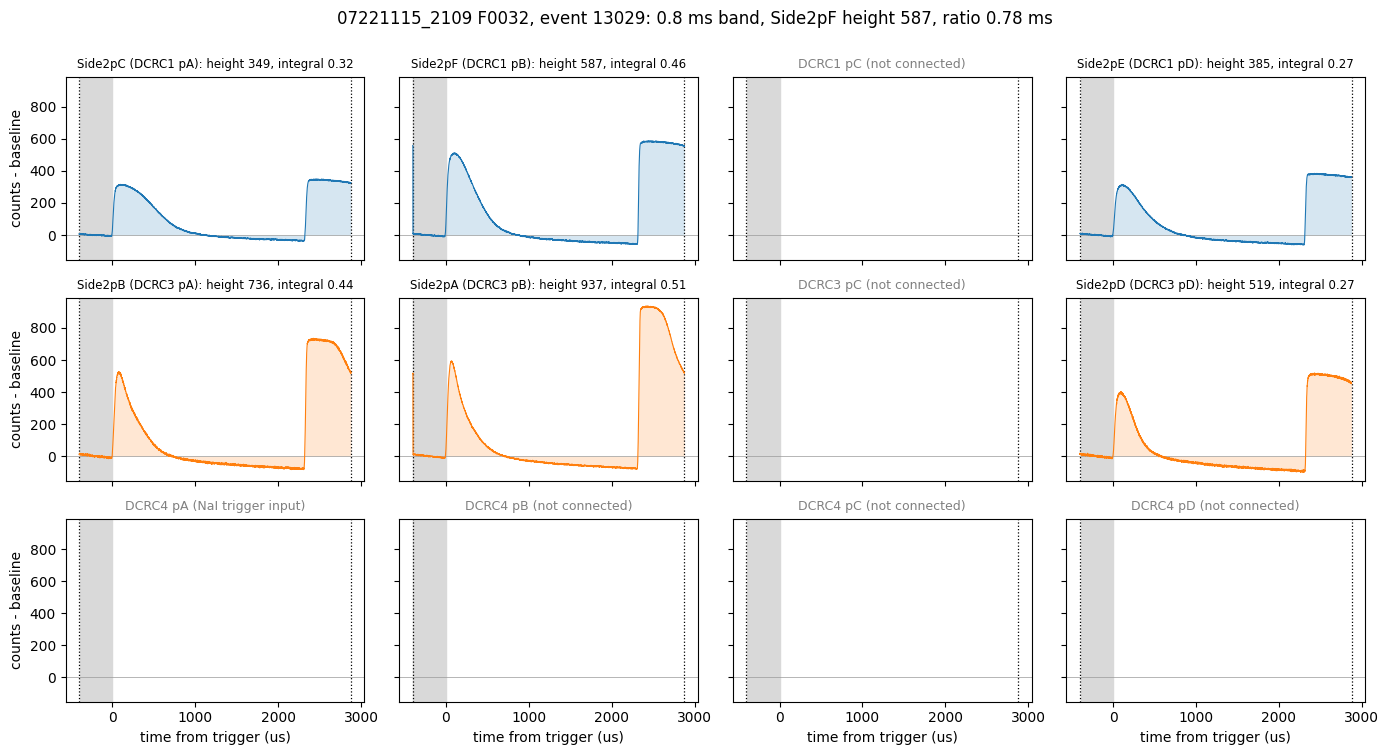

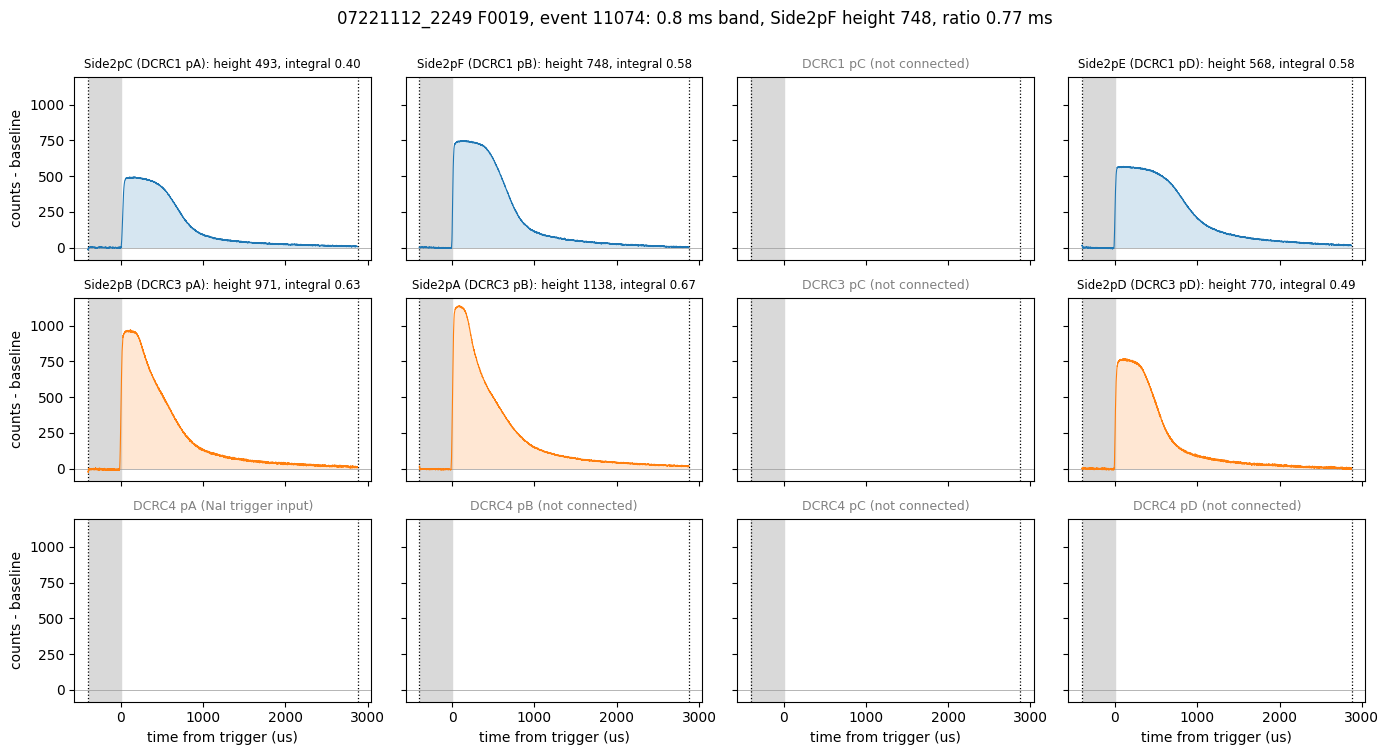

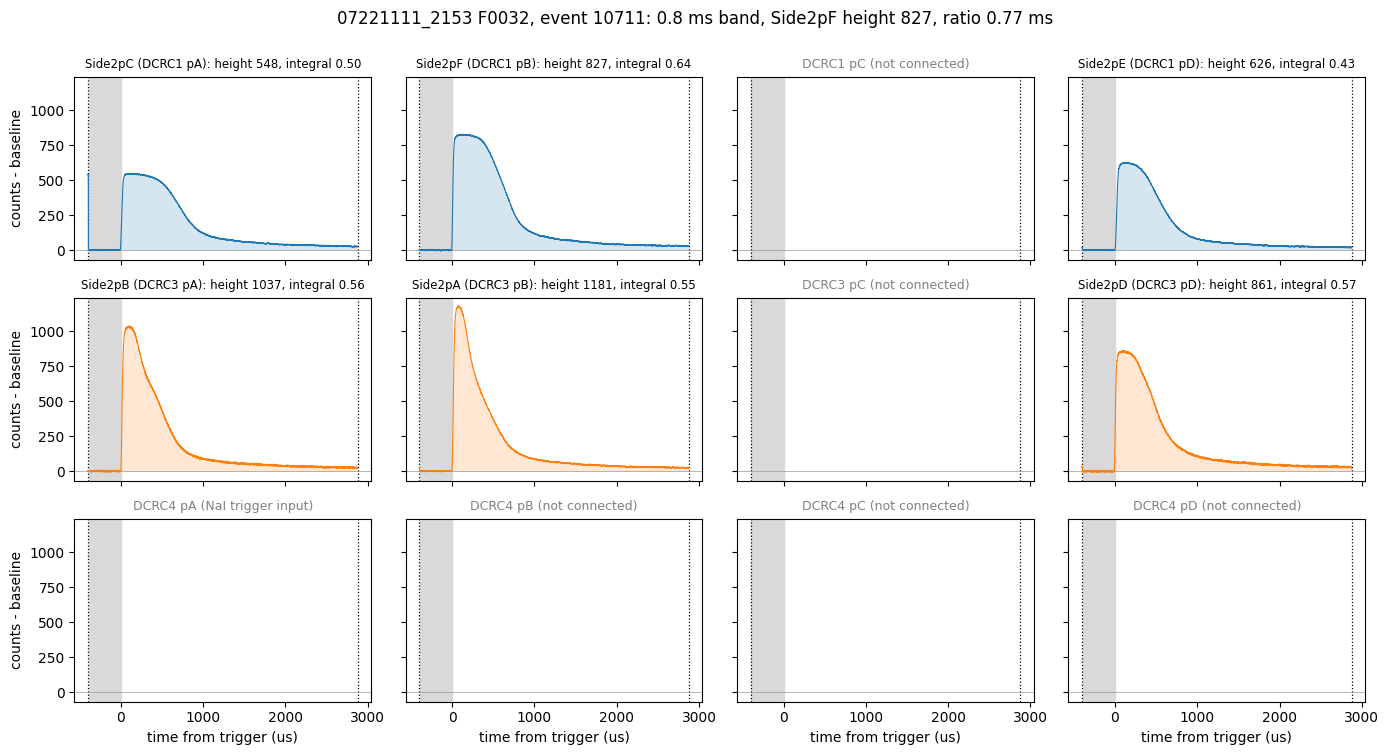

In [9]:
import goldpan.channels as pch

N_ALONG, SEED_ALONG = 8, 2
edges = np.linspace(100, H_MAX, N_ALONG + 1)        # from 100 counts: below it the window holds little of the band
rng = np.random.default_rng(SEED_ALONG)
along = np.array([rng.choice(np.flatnonzero(line & (HF >= a) & (HF < b))) for a, b in zip(edges[:-1], edges[1:])])
SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]
INFO = {key: pch.channel_info(*key) for key in KEYS}

full = {}
for s, dmp in sorted({(SER[i], DMP[i]) for i in along}):
    ev = idx.read(RAW / (dmp if dmp.startswith(s) else f"{s}_{dmp}"), detector_name="NAI-S2", channels=SENSORS, config=DCRC_RUN76)
    numbers = np.asarray(ev.quantities["event"])
    segment = {name: seg for (name, seg) in ev.traces}
    for i in along:
        if (SER[i], DMP[i]) == (s, dmp):
            j = int(np.flatnonzero(numbers == EVT[i])[0])
            full[i] = {}
            for name in SENSORS:
                x = np.asarray(ev.traces[(name, segment[name])][j], dtype=float)
                full[i][name] = x - x[g:p].mean()
worst = max(abs(full[i][f"Side2p{k}"].sum() * DCRC_RUN76.sample_period_s - I[k][i]) for i in along for k in LETTERS)
print(f"{len(along)} events; largest difference from the processed integrals: {worst:.1e}")

BOARD_COLOUR = {"DCRC1": "C0", "DCRC3": "C1"}
for i in along:
    lo = min(f.min() for f in full[i].values())
    hi = max(f.max() for f in full[i].values())
    pad = 0.05 * (hi - lo)
    fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey=True)
    for key, ax in zip(KEYS, axes.flat):
        c = INFO[key]
        ax.axvspan(t_us[g], 0, color="0.85", zorder=0)
        for t in (t_us[0], t_us[-1]):
            ax.axvline(t, color="k", linestyle=":", linewidth=0.9)
        ax.axhline(0, color="0.6", linewidth=0.5)
        if c.role != pch.SENSOR:
            what = "NaI trigger input" if c.role == pch.NAI_TRIGGER else "not connected"
            ax.set_title(f"{c.dcrc} {c.board_input} ({what})", fontsize=9, color="0.5")
            continue
        f, k = full[i][c.name], c.name[-1]
        ax.fill_between(t_us, f, 0, color=BOARD_COLOUR[c.dcrc], alpha=0.18, linewidth=0)
        ax.plot(t_us, f, linewidth=0.8, color=BOARD_COLOUR[c.dcrc])
        ax.set_title(f"{c.name} ({c.dcrc} {c.board_input}): height {H[k][i]:.0f}, integral {I[k][i]:.2f}", fontsize=8.5)
    for ax in axes[-1]:
        ax.set_xlabel("time from trigger (us)")
    for ax in axes[:, 0]:
        ax.set_ylabel("counts - baseline")
    axes[0, 0].set_ylim(lo - pad, hi + pad)
    fig.suptitle(f"{SER[i]} {DMP[i]}, event {EVT[i]}: 0.8 ms band, Side2pF height {HF[i]:.0f}, ratio {RF[i]:.2f} ms", y=1.0)
    fig.tight_layout()
    plt.show()

The same events overlaid, channel by channel, each divided by its Side2pF height, to see whether the shape changes along the band.

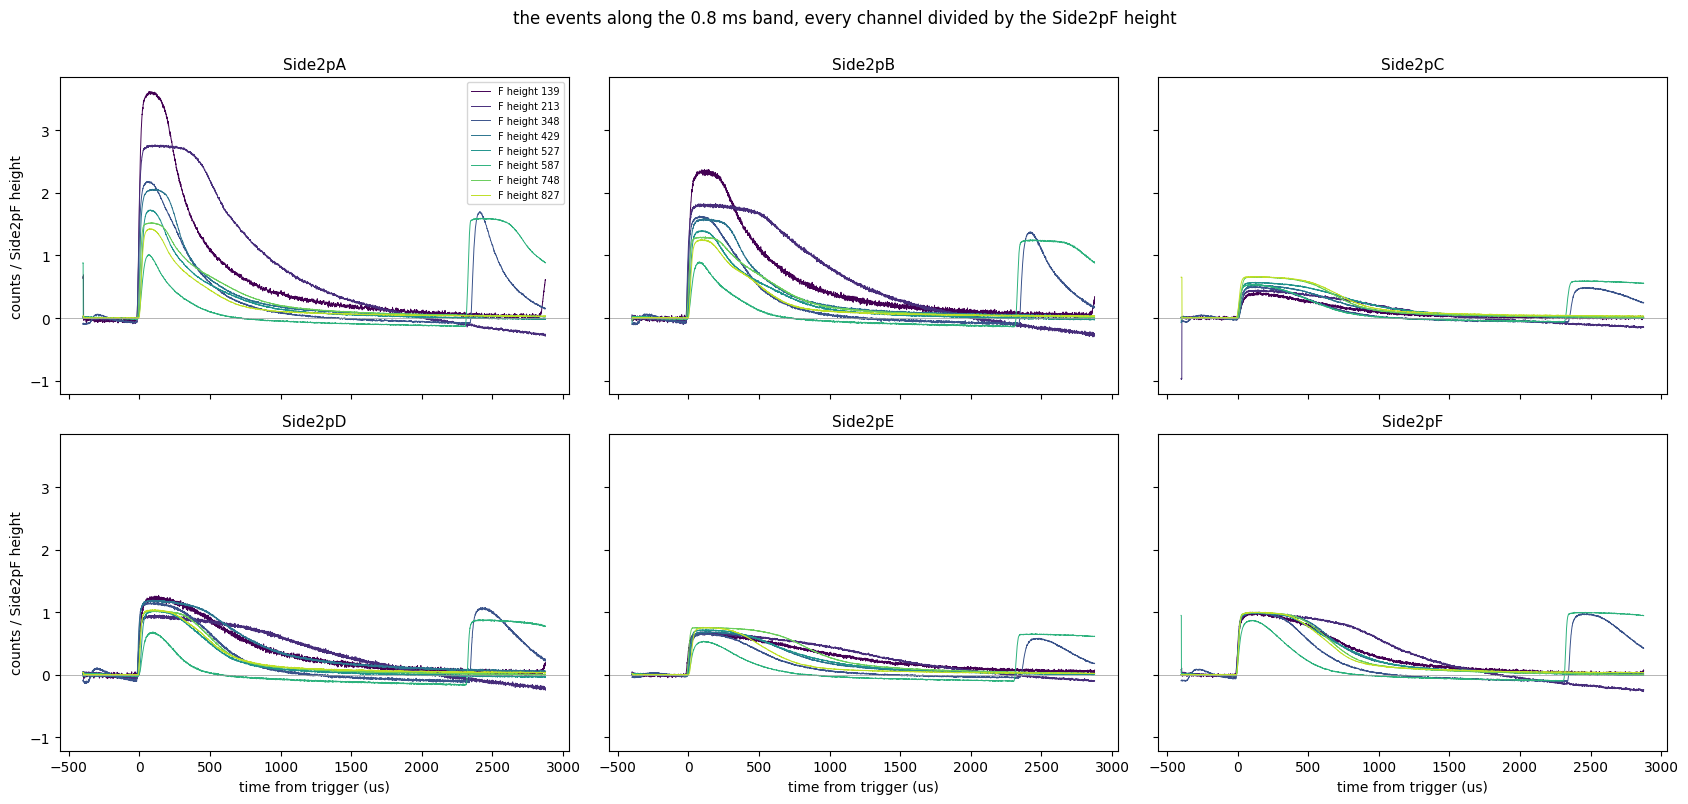

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True, sharey=True)
shades = plt.get_cmap("viridis")(np.linspace(0, 0.9, len(along)))
for ax, k in zip(axes.flat, LETTERS):
    for i, col in zip(along, shades):
        ax.plot(t_us, full[i][f"Side2p{k}"] / HF[i], color=col, linewidth=0.7, label=f"F height {HF[i]:.0f}")
    ax.axhline(0, color="0.6", linewidth=0.5)
    ax.set_title(f"Side2p{k}", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("time from trigger (us)")
for ax in axes[:, 0]:
    ax.set_ylabel("counts / Side2pF height")
axes[0, 0].legend(fontsize=7)
fig.suptitle("the events along the 0.8 ms band, every channel divided by the Side2pF height", y=1.0)
fig.tight_layout()
plt.show()

**What to look for.** Where each channel leaves the straight line through the origin (the start of saturation), how far below the saturated height that happens, and whether the channels agree on it in units of their own saturated height. Events far off the main band (a large height with a small integral, or a negative integral) are pile-up, a pulse in the pretrigger window, or a glitch; `low-integral-traces.ipynb` shows how to draw a few of them.

## Where the 0.8 ms band events are on the face

The events of the 0.8 ms band cut (`line`, Side2pF height 50 to 850) placed on the face with the delays between the 20 % rise times, as in `positions-82v-dcrc1pb.ipynb`: `xdel = t_E - (t_C + t_D) / 2 - 1 us`, `ydel = 0.866 (t_D - t_C) + 9 us` (the offsets of Fritts's code), with the detector drawn underneath at the placeholder scale `R_US` = 14 us and the `x` axis reversed (`C` upper left, `D` lower left, `E` right). The delays and the selection come from `spots_82v.load()`. Of the selection of the position notebook only the conditions on the times are applied (all six 20 % times present and within 60 us of each other), not `total > 2`, so that the small events of the band are kept. On the right, all the real triggers with the same conditions, for comparison; then the two normalised and divided, to show where the band events are more frequent than the rest. The two spot circles of `spots_82v.py` are drawn in red.

0.8 ms band: 63,503 events, 61,837 with six good 20 % times; all real triggers with them: 1,346,035


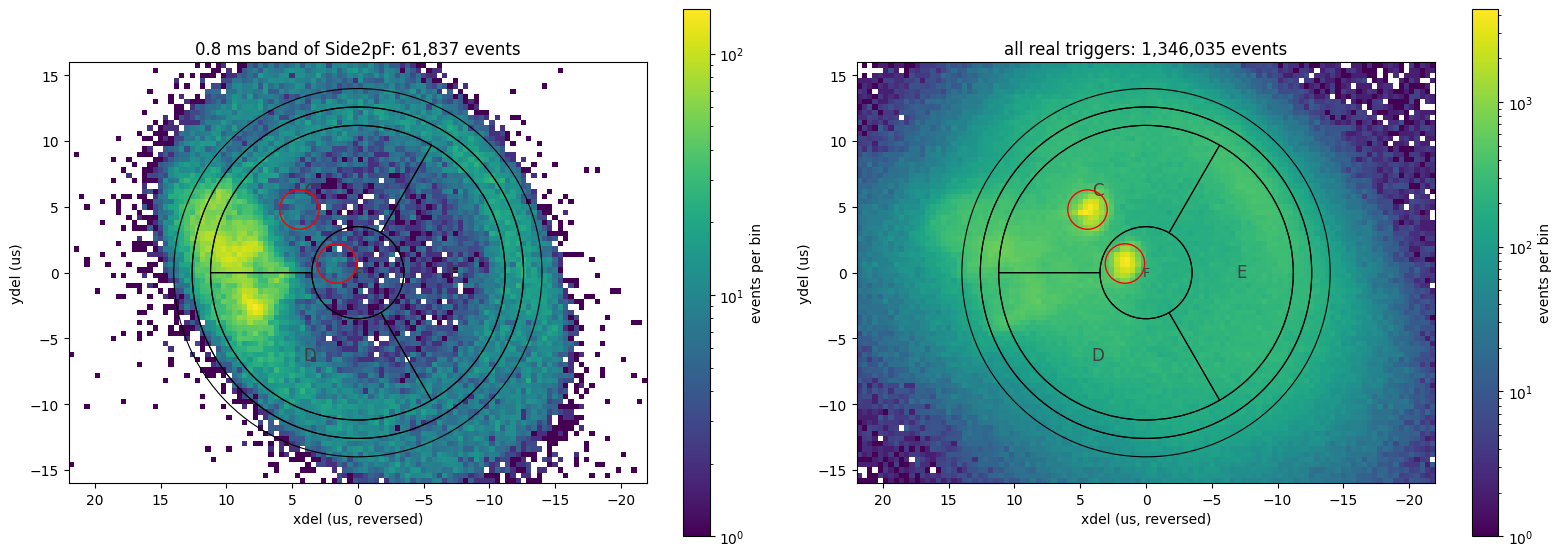

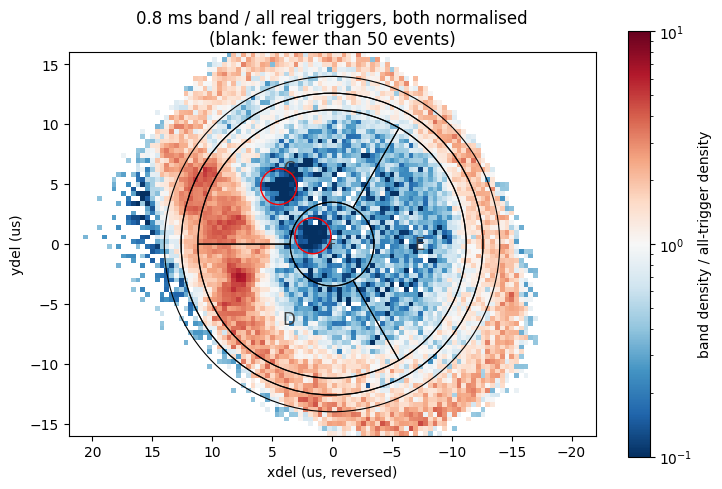

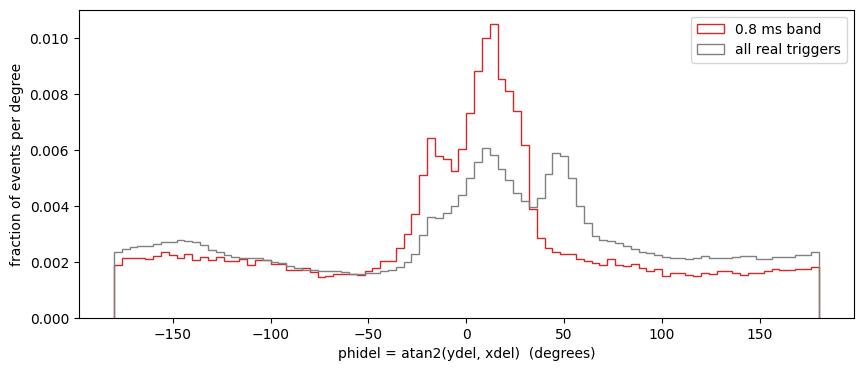

In [11]:
from matplotlib.patches import Circle, Wedge

from spots_82v import SPOTS, WINDOW, load

dl = load()
xdel, ydel = dl["xdel"][real], dl["ydel"][real]
Tt = np.column_stack([dl["t"][k][real] for k in LETTERS])
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)             # an event with no time at all has an all-nan median
    timed = np.isfinite(Tt).all(axis=1) & (np.abs(Tt - np.nanmedian(Tt, axis=1, keepdims=True)) < WINDOW).all(axis=1)
pos_band = line & timed
print(f"0.8 ms band: {line.sum():,} events, {pos_band.sum():,} with six good 20 % times; all real triggers with them: {timed.sum():,}")

REGIONS = {"A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360), "C": (0.25, 0.80, 60, 180),
           "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60), "F": (0.00, 0.25, 0, 360)}
R_US, XR, YR = 14.0, 22, 16

def draw_detector_mirrored(ax, radius=R_US):
    for k, (r_in, r_out, a0, a1) in REGIONS.items():
        ax.add_patch(Wedge((0, 0), r_out * radius, 180 - a1, 180 - a0, width=(r_out - r_in) * radius,
                           facecolor="none", edgecolor="k", linewidth=0.8, zorder=3))
        if k in "CDE":
            a = np.deg2rad((a0 + a1) / 2)
            ax.text(-0.52 * radius * np.cos(a), 0.52 * radius * np.sin(a), k, ha="center", va="center", fontsize=12, color="0.25", zorder=5)
    ax.text(0, 0, "F", ha="center", va="center", fontsize=9, color="0.25", zorder=5)
    for x0, y0, r in SPOTS.values():
        ax.add_patch(Circle((x0, y0), r, facecolor="none", edgecolor="r", linewidth=1.0, zorder=6))
    ax.set_xlim(XR, -XR)
    ax.set_ylim(-YR, YR)
    ax.set_aspect("equal")
    ax.set_xlabel("xdel (us, reversed)")
    ax.set_ylabel("ydel (us)")

BX, BY = np.linspace(-XR, XR, 111), np.linspace(-YR, YR, 81)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, m, title in ((axes[0], pos_band, f"0.8 ms band of Side2pF: {pos_band.sum():,} events"),
                     (axes[1], timed, f"all real triggers: {timed.sum():,} events")):
    h = ax.hist2d(xdel[m], ydel[m], bins=[BX, BY], cmap="viridis", norm=colors.LogNorm(), cmin=1, zorder=2)
    draw_detector_mirrored(ax)
    ax.set_title(title)
    fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
fig.tight_layout()
plt.show()

# the band's share of the events at each place: its normalised density over that of all real triggers
nb_, _, _ = np.histogram2d(xdel[pos_band], ydel[pos_band], bins=[BX, BY])
na_, _, _ = np.histogram2d(xdel[timed], ydel[timed], bins=[BX, BY])
ratio = np.where(na_ >= 50, (nb_ / pos_band.sum()) / np.maximum(na_ / timed.sum(), 1e-12), np.nan)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
c = ax.pcolormesh(BX, BY, ratio.T, cmap="RdBu_r", norm=colors.LogNorm(vmin=0.1, vmax=10), zorder=2)
draw_detector_mirrored(ax)
ax.set_title("0.8 ms band / all real triggers, both normalised" + chr(10) + "(blank: fewer than 50 events)")
fig.colorbar(c, ax=ax, shrink=0.85, label="band density / all-trigger density")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for m, col, lab in ((pos_band, "C3", "0.8 ms band"), (timed, "0.5", "all real triggers")):
    ax.hist(np.degrees(np.arctan2(ydel[m], xdel[m])), bins=np.linspace(-180, 180, 91), histtype="step", density=True, color=col, label=lab)
ax.set_xlabel("phidel = atan2(ydel, xdel)  (degrees)")
ax.set_ylabel("fraction of events per degree")
ax.legend()
plt.show()